In [1]:
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("..")
from lens.raytrace import best_spot
from lens.design import R2_for
from lens.optimize import deriv, gradient_descent

In [2]:
print(best_spot([(0, 25, 1.5), (5, np.inf, 1.0)]))
print(best_spot([(0, 50, 1.5), (5, -50, 1.0)]))

(np.float64(50.2), np.float64(0.07652434705479158))
(np.float64(52.150000000000006), np.float64(0.10242148707533795))


best_spot gives the same answers as the scan in part 1 exercise 6: the plano-convex lens focuses best at 50.2 mm with a 0.0765 mm spot, and the biconvex lens at 52.15 mm with 0.1024 mm.

In [3]:
R2 = R2_for(25, 5, 50)
print(R2)

inf


In [4]:
R1, t, n = 50, 5, 1.5
R2 = R2_for(R1, t, 50)
f = 1 / ((n - 1) * (1 / R1 - 1 / R2 + (n - 1) * t / (n * R1 * R2)))
print(R2, f)

-48.333333333333336 50.0


for r1 = 25 and t = 5, r2_for gives infinity, which is a flat back. that makes sense, because a plano-convex lens with r = 25 already has f = r / (n − 1) = 50, so no back curve is needed.
for r1 = 50, the back has to curve too (r2 = −48.33) to bring the focal length back to 50. the lensmaker formula confirms f = 50.0.

In [5]:
def spot_f50(R1, t):
    R2 = R2_for(R1, t, 50)
    surfaces = [(0, R1, 1.5), (t, R2, 1.0)]
    position, spot = best_spot(surfaces)
    return spot

R1s = np.linspace(20, 45, 101)
spots = []
for R1 in R1s:
    spots.append(spot_f50(R1, 5))
spots = np.array(spots)
best = np.argmin(spots)
print(R1s[best], spots[best], R2_for(R1s[best], 5, 50))

29.5 0.0688061864574251 -154.6296296296296


trying 101 front radii (with the back calculated so f stays 50), the sharpest lens has r1 = 29.5 mm and r2 = −154.6 mm, with a spot of 0.0688 mm. that’s about 10% sharper than the plano-convex lens (0.0765 mm) at the same focal length, so a slightly curved back helps.

29.7564163252467 -147.6413529524411 0.06882648458131624


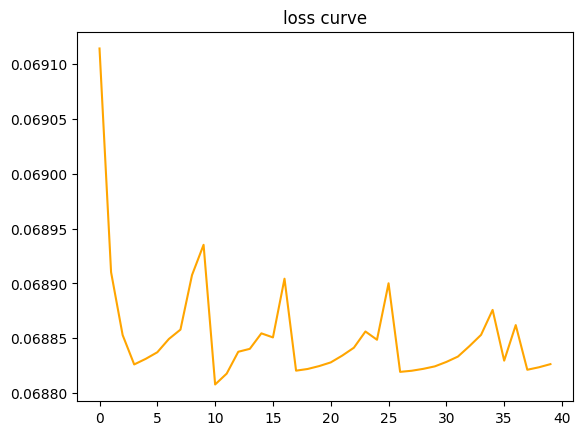

In [6]:
def spot_t5(R1):
    return spot_f50(R1, 5)

R1, spots = gradient_descent(spot_t5, 25, 1000, 40)
R2 = R2_for(R1, t = 5, f = 50)
print(R1, R2, spots[39])
plt.plot(range(40), spots, color="orange")
plt.title("loss curve")
plt.show()

gradient descent found nearly the same lens as brute force: r1 = 29.76 mm, r2 = −147.6 mm, spot 0.0688 mm, in 40 steps instead of 101 tries.

In [7]:
R1, t = 25.0, 5.0
spotss = []
for i in range(60):
    def loss_R1(x):
        return spot_f50(x, t)
    def loss_t(x):
        return spot_f50(R1, x)
    slope_R1 = deriv(loss_R1, R1)
    slope_t = deriv(loss_t, t)
    R1 = R1 - 300 * slope_R1
    t = np.clip(t - 300 * slope_t, 2, 6)
    spotss.append(spot_f50(R1, t))

print(R1, t, R2_for(R1, t, 50), spotss[-1])

29.496365418264766 6.0 -152.88106537433143 0.06836936980208858


with two knobs (r1 and t), the optimizer reached r1 = 29.5 mm, t = 6 mm, r2 = −152.9 mm and a spot of 0.0684 mm, while f stayed exactly 50.

the thickness constraint is active: t went straight to the 6 mm limit. a thicker lens helps slightly here (thicker glass gives the rays a bit more room to bend gently), so the optimizer keeps pushing t up and the rule stops it.

the final lens is a “best-form lens”: strongly curved at the front (r1 ≈ 29.5) and only slightly curved at the back (r2 ≈ −153). it beats the 0.077 mm floor of the plano-convex lens by about 10%, because the bending is shared between both surfaces instead of mostly happening at the front.